In [45]:
#-*- coding:utf-8 -*-
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import os


In [46]:
# 创建保存图像文件夹
os.makedirs('res', exist_ok=True)

# 超参数设置
batch_size = 2048
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")
print(f"批大小: {batch_size}")

transform = transforms.Compose([
    transforms.ToTensor(),
])
# 加载数据
train_loader = torch.utils.data.DataLoader(
    datasets.MNIST('data', train=True, download=True, transform=transform),
    batch_size=batch_size, shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('data', train=False, transform=transform),
    batch_size=batch_size, shuffle=False
)

print("训练数据形状:", train_loader.dataset.data.shape)
print("测试数据形状:", test_loader.dataset.data.shape)
print("类别数量: 10 (数字0‑9)")


使用设备: cpu
批大小: 2048
训练数据形状: torch.Size([60000, 28, 28])
测试数据形状: torch.Size([10000, 28, 28])
类别数量: 10 (数字0‑9)


训练样本示例:


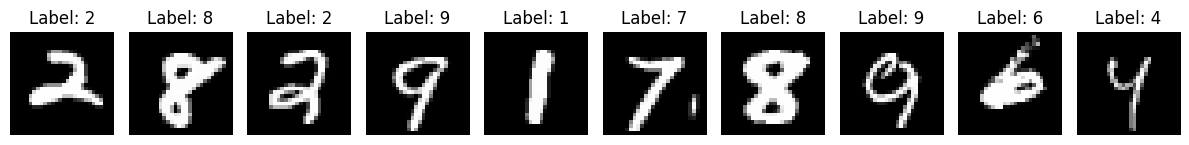

In [47]:
# 数据可视化
def show_samples(loader, num_samples=10):
    data_iter = iter(loader)
    images, labels = next(data_iter)

    plt.figure(figsize=(12, 3))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i+1)
        plt.imshow(images[i].squeeze(), cmap='gray')
        plt.title(f'Label: {labels[i].item()}')
        plt.axis('off')
    plt.tight_layout()
    plt.show()

print("训练样本示例:")
show_samples(train_loader)


In [48]:
# MLP 模型
class mlp(nn.Module):
    def __init__(self):
        super(mlp,self).__init__()
        self.l1 = nn.Linear(784, 128)
        self.l2 = nn.Linear(128,10)

    def forward(self,x):
        x = F.relu(self.l1(x))
        x = self.l2(x)
        return x

model = mlp().to(device)
optimizer = optim.SGD(model.parameters(), lr=0.1, momentum=0.9)

print("模型结构:")
print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f"\n总参数数量: {total_params:,}")


模型结构:
mlp(
  (l1): Linear(in_features=784, out_features=128, bias=True)
  (l2): Linear(in_features=128, out_features=10, bias=True)
)

总参数数量: 101,770


In [49]:
epochs = 30
train_losses = []
train_accuracies = []

print("开始训练...")
print("---")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (x, y) in enumerate(train_loader):
        x, y = x.view(x.shape[0], -1).to(device), y.to(device)

        optimizer.zero_grad()
        output = model(x)
        loss = F.cross_entropy(output, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        pred = output.max(1, keepdim=True)[1]
        correct += pred.eq(y.view_as(pred)).sum().item()
        total += y.size(0)

    avg_loss = running_loss / len(train_loader)
    accuracy = 100. * correct / total

    train_losses.append(avg_loss)
    train_accuracies.append(accuracy)

    print(f"Epoch [{epoch+1:2d}/{epochs}] - Loss: {avg_loss:.4f} - Accuracy: {accuracy:.2f}%")

print("---")
print("训练完成!")


开始训练...
---
Epoch [ 1/30] - Loss: 1.1662 - Accuracy: 69.76%
Epoch [ 2/30] - Loss: 0.3790 - Accuracy: 89.13%
Epoch [ 3/30] - Loss: 0.3040 - Accuracy: 91.23%
Epoch [ 4/30] - Loss: 0.2719 - Accuracy: 92.24%
Epoch [ 5/30] - Loss: 0.2451 - Accuracy: 92.98%
Epoch [ 6/30] - Loss: 0.2238 - Accuracy: 93.62%
Epoch [ 7/30] - Loss: 0.2046 - Accuracy: 94.15%
Epoch [ 8/30] - Loss: 0.1864 - Accuracy: 94.70%
Epoch [ 9/30] - Loss: 0.1722 - Accuracy: 95.14%
Epoch [10/30] - Loss: 0.1599 - Accuracy: 95.45%
Epoch [11/30] - Loss: 0.1477 - Accuracy: 95.77%
Epoch [12/30] - Loss: 0.1390 - Accuracy: 96.08%
Epoch [13/30] - Loss: 0.1291 - Accuracy: 96.34%
Epoch [14/30] - Loss: 0.1219 - Accuracy: 96.58%
Epoch [15/30] - Loss: 0.1160 - Accuracy: 96.80%
Epoch [16/30] - Loss: 0.1091 - Accuracy: 96.97%
Epoch [17/30] - Loss: 0.1049 - Accuracy: 97.05%
Epoch [18/30] - Loss: 0.0991 - Accuracy: 97.25%
Epoch [19/30] - Loss: 0.0948 - Accuracy: 97.39%
Epoch [20/30] - Loss: 0.0902 - Accuracy: 97.55%
Epoch [21/30] - Loss: 0.0873

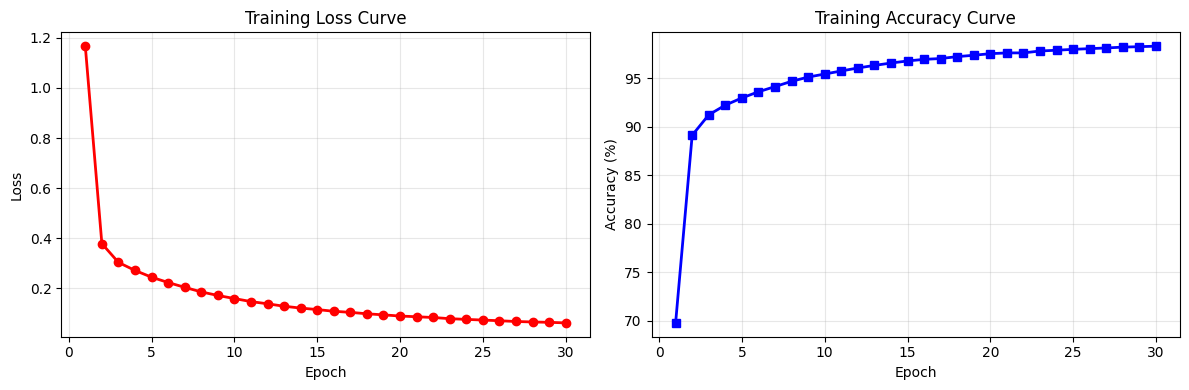

In [51]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(range(1, epochs+1), train_losses, marker='o', color='red', linewidth=2)
ax1.set_title('Training Loss Curve')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, alpha=0.3)

ax2.plot(range(1, epochs+1), train_accuracies, marker='s', color='blue', linewidth=2)
ax2.set_title('Training Accuracy Curve')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('res/training_curves.png', dpi=300, bbox_inches='tight')
plt.show()


In [52]:
model.eval()
correct = 0
test_loss = 0
y_true = []
y_pred = []

print("开始测试...")
with torch.no_grad():
    for batch_idx, (x, y) in enumerate(test_loader):
        x, y = x.view(x.shape[0], -1).to(device), y.to(device)
        output = model(x)
        test_loss += F.cross_entropy(output, y)
        pred = output.max(1, keepdim=True)[1]
        correct += pred.eq(y.view_as(pred)).sum().item()
        y_true.extend(y.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())

test_loss = test_loss / (batch_idx + 1)
acc = 100. * correct / len(test_loader.dataset)

print("---")
print('测试结果:')
print(f'测试损失: {test_loss:.4f}')
print(f'测试准确率: {acc:.2f}%')
print(f'正确样本数: {correct}/{len(test_loader.dataset)}')
print("---")



开始测试...
---
测试结果:
测试损失: 0.0859
测试准确率: 97.27%
正确样本数: 9727/10000
---


<Figure size 800x600 with 0 Axes>

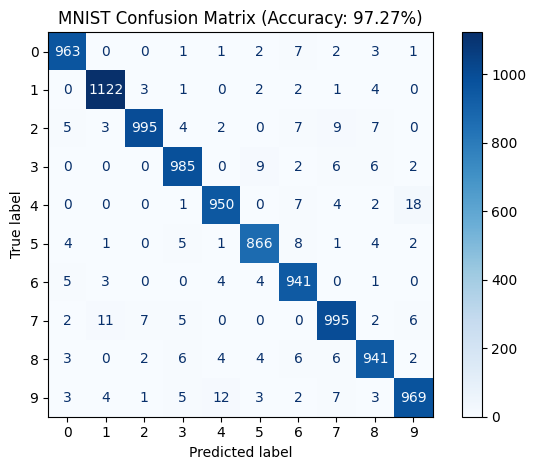

In [53]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))

plt.figure(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title(f'MNIST Confusion Matrix (Accuracy: {acc:.2f}%)')
plt.tight_layout()
plt.savefig('res/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


测试样本预测结果:


<Figure size 640x480 with 0 Axes>

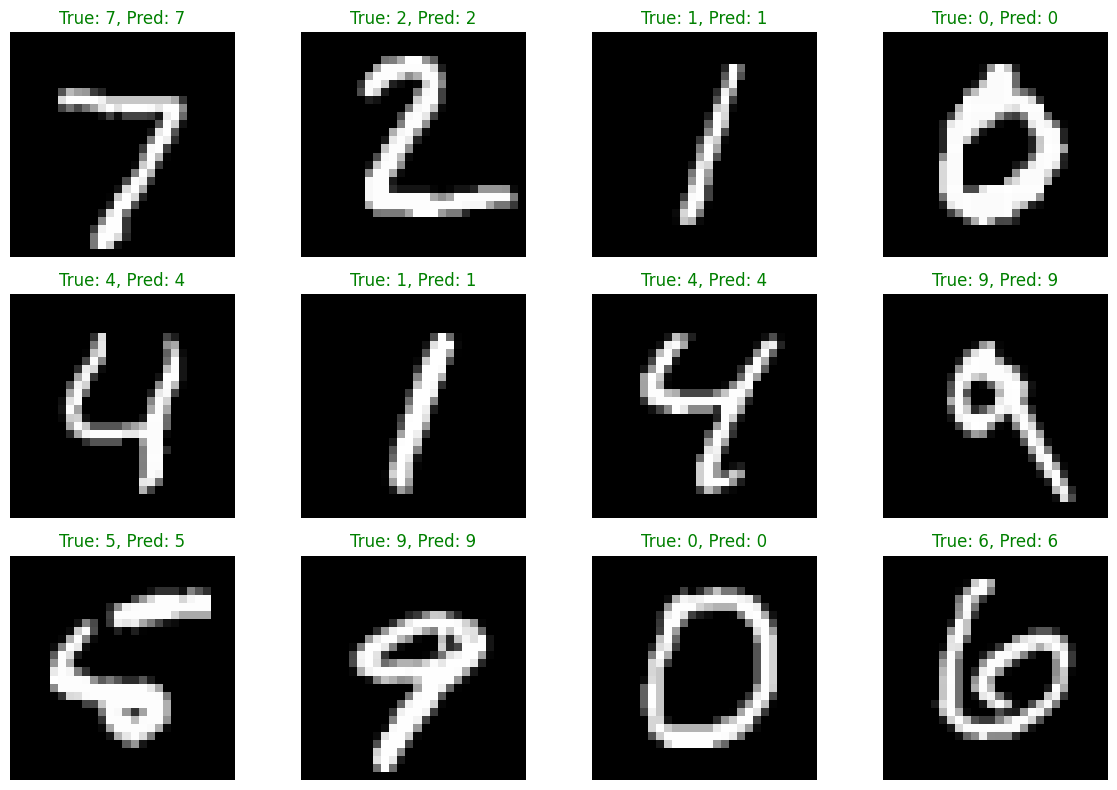

In [54]:
def show_predictions(loader, model, device, num_samples=12):
    model.eval()
    data_iter = iter(loader)
    images, labels = next(data_iter)
    sample_images = images[:num_samples]
    sample_labels = labels[:num_samples]

    with torch.no_grad():
        outputs = model(sample_images.view(num_samples, -1).to(device))
        _, predicted = torch.max(outputs, 1)

    plt.clf()  # 新增：清除历史画布残留，解决单元格看不到图片的bug
    plt.figure(figsize=(12, 8))
    for i in range(num_samples):
        plt.subplot(3, 4, i+1)
        plt.imshow(sample_images[i].squeeze(), cmap='gray')
        color = 'green' if predicted[i] == sample_labels[i] else 'red'
        plt.title(f'True: {sample_labels[i]}, Pred: {predicted[i]}', color=color)
        plt.axis('off')
    plt.tight_layout()
    plt.savefig('res/predictions.png', dpi=300, bbox_inches='tight')
    plt.show()

print("测试样本预测结果:")
show_predictions(test_loader, model, device)



In [55]:
torch.save(model.state_dict(), 'res/mnist_mlp_model.pth')

print("---")
print("实验总结:")
print(f"模型已保存: res/mnist_mlp_model.pth")
print(f"训练曲线已保存: res/training_curves.png")
print(f"混淆矩阵已保存: res/confusion_matrix.png")
print(f"预测示例已保存: res/predictions.png")
print(f"最终测试准确率: {acc:.2f}%")
print("---")


---
实验总结:
模型已保存: res/mnist_mlp_model.pth
训练曲线已保存: res/training_curves.png
混淆矩阵已保存: res/confusion_matrix.png
预测示例已保存: res/predictions.png
最终测试准确率: 97.27%
---
